In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

obraz = cv2.imread("obraz_testowy.jpg")
obraz_rgb = cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)
naroza = cv2.imread("obraz_naroza.jpg")
naroza_rgb = cv2.cvtColor(naroza, cv2.COLOR_BGR2RGB)
naroza_szare = cv2.cvtColor(naroza, cv2.COLOR_BGR2GRAY)

Oznaczone piksele: 17709


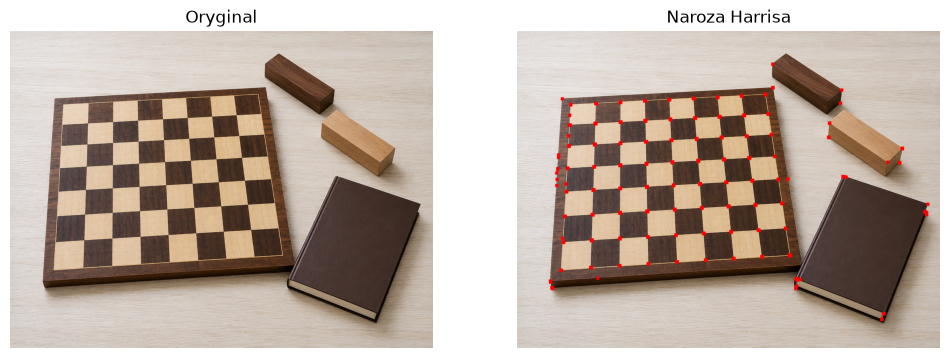

In [3]:
odpowiedz = cv2.cornerHarris(np.float32(naroza_szare), blockSize=2, ksize=3, k=0.04)
odpowiedz = cv2.dilate(odpowiedz, None, iterations=5)
zaznaczone = naroza_rgb.copy()
zaznaczone[odpowiedz > 0.01 * odpowiedz.max()] = [255, 0, 0]
print("Oznaczone piksele:", np.sum(odpowiedz > 0.01 * odpowiedz.max()))
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(naroza_rgb)
plt.title("Oryginal")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(zaznaczone)
plt.title("Naroza Harrisa")
plt.axis("off")
plt.show()

Liczba znalezionych punktow: 80


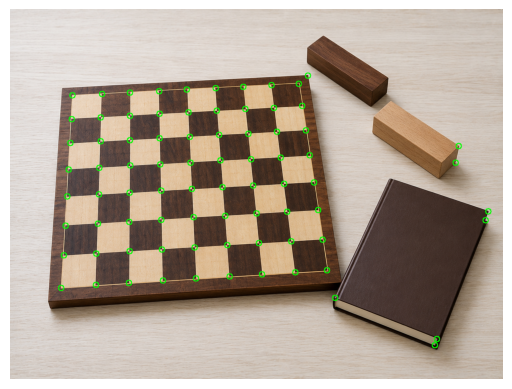

In [4]:
punkty = cv2.goodFeaturesToTrack(
    naroza_szare, maxCorners=80, qualityLevel=0.05, minDistance=15
)
punkty = punkty.reshape(-1, 2).astype(int)
print("Liczba znalezionych punktow:", len(punkty))
zaznaczone2 = naroza_rgb.copy()
for x, y in punkty:
    cv2.circle(zaznaczone2, (x, y), 8, (0, 255, 0), 2)
plt.imshow(zaznaczone2)
plt.axis("off")
plt.show()

Liczba punktow kluczowych: 500
Rozmiar tablicy deskryptorow: (500, 32)


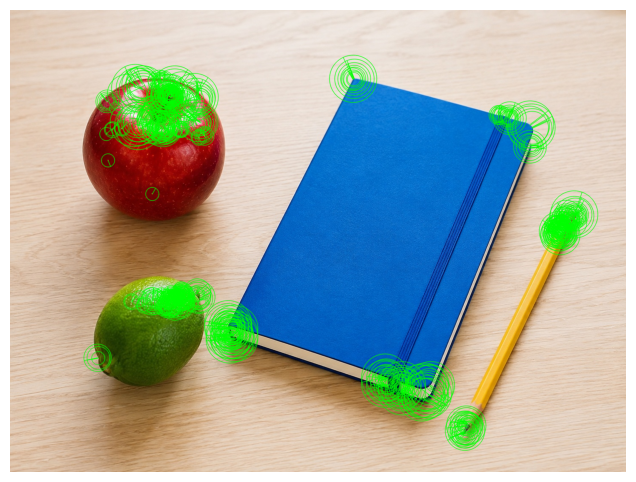

In [5]:
szary1 = cv2.cvtColor(obraz_rgb, cv2.COLOR_RGB2GRAY)
orb = cv2.ORB_create(nfeatures=500)
kp1, des1 = orb.detectAndCompute(szary1, None)
print("Liczba punktow kluczowych:", len(kp1))
print("Rozmiar tablicy deskryptorow:", des1.shape)
z_punktami = cv2.drawKeypoints(
    obraz_rgb,
    kp1,
    None,
    color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
)
plt.figure(figsize=(10, 6))
plt.imshow(z_punktami)
plt.axis("off")
plt.show()

Liczba dopasowan: 366
Srednia odleglosc 30 najlepszych: 8.8


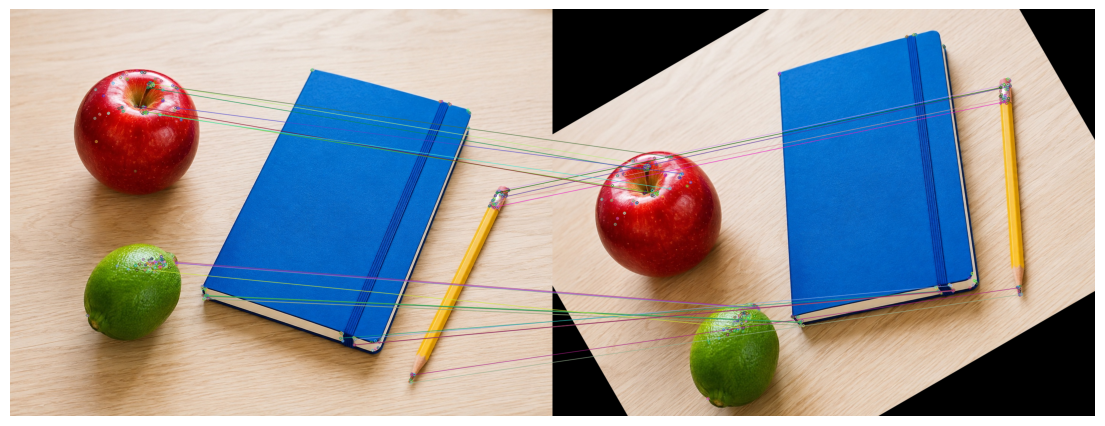

In [6]:
def przeksztalc(obraz_wej, kat, skala):
    (wys, szer) = obraz_wej.shape[:2]
    srodek = (szer // 2, wys // 2)
    macierz = cv2.getRotationMatrix2D(srodek, kat, skala)
    return cv2.warpAffine(obraz_wej, macierz, (szer, wys))


obraz2_rgb = przeksztalc(obraz_rgb, 30, 1.0)
szary2 = cv2.cvtColor(obraz2_rgb, cv2.COLOR_RGB2GRAY)

kp2, des2 = orb.detectAndCompute(szary2, None)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
dopasowania = bf.match(des1, des2)
dopasowania = sorted(dopasowania, key=lambda d: d.distance)
print("Liczba dopasowan:", len(dopasowania))
najlepsze = dopasowania[:30]
print(
    "Srednia odleglosc 30 najlepszych:",
    round(np.mean([d.distance for d in najlepsze]), 1),
)
wizualizacja = cv2.drawMatches(obraz_rgb, kp1, obraz2_rgb, kp2, najlepsze, None)
plt.figure(figsize=(14, 6))
plt.imshow(wizualizacja)
plt.axis("off")
plt.show()

Liczba dopasowan (obrot): 366
Liczba dopasowan (obrot i skala 0.4): 153
Srednia odleglosc 30 najlepszych: 14.2


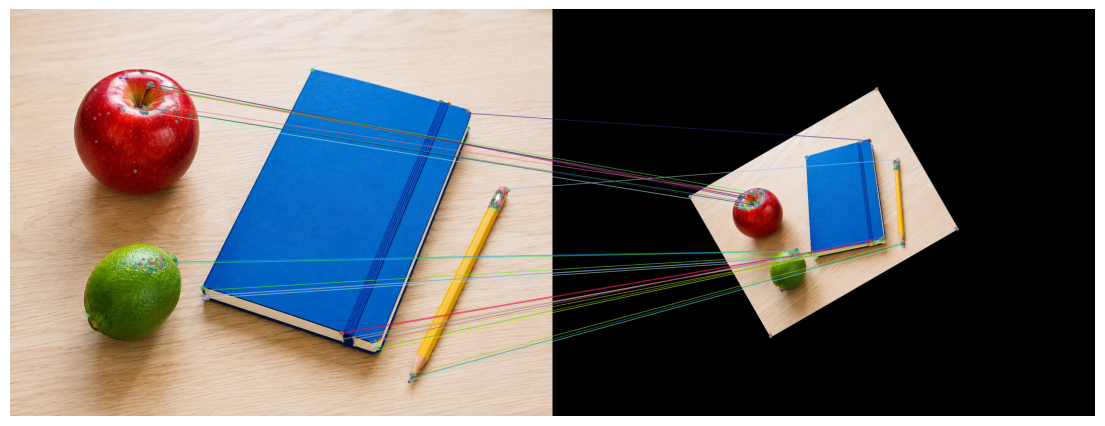

In [7]:
obraz3_rgb = przeksztalc(obraz_rgb, 30, 0.4)
szary3 = cv2.cvtColor(obraz3_rgb, cv2.COLOR_RGB2GRAY)
kp3, des3 = orb.detectAndCompute(szary3, None)
dopasowania3 = sorted(bf.match(des1, des3), key=lambda d: d.distance)
print("Liczba dopasowan (obrot):", len(dopasowania))
print("Liczba dopasowan (obrot i skala 0.4):", len(dopasowania3))
naj3 = dopasowania3[:30]
print(
    "Srednia odleglosc 30 najlepszych:", round(np.mean([d.distance for d in naj3]), 1)
)
wizualizacja3 = cv2.drawMatches(obraz_rgb, kp1, obraz3_rgb, kp3, naj3, None)
plt.figure(figsize=(14, 6))
plt.imshow(wizualizacja3)
plt.axis("off")
plt.show()

# Zadanie 1

Oznaczone piksele: 26685


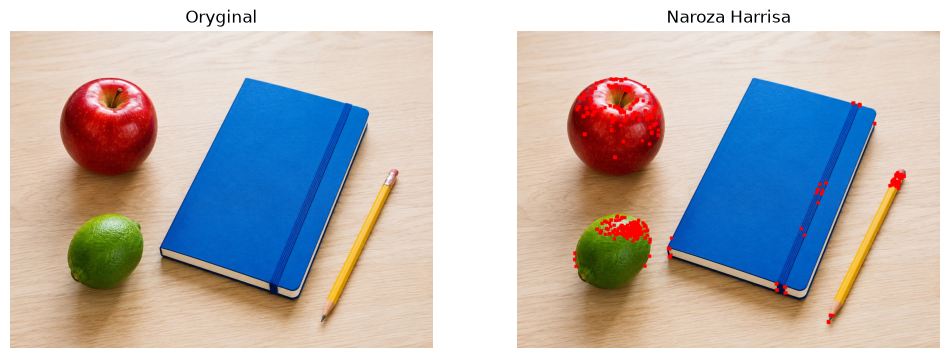

In [11]:
obraz = cv2.imread("obraz_testowy.jpg")

obraz_rgb = cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)
obraz_szare = cv2.cvtColor(obraz, cv2.COLOR_BGR2GRAY)

odpowiedz = cv2.cornerHarris(np.float32(obraz_szare), blockSize=2, ksize=3, k=0.04)
odpowiedz = cv2.dilate(odpowiedz, None, iterations=5)
zaznaczone = obraz_rgb.copy()
zaznaczone[odpowiedz > 0.01 * odpowiedz.max()] = [255, 0, 0]
print("Oznaczone piksele:", np.sum(odpowiedz > 0.01 * odpowiedz.max()))
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(obraz_rgb)
plt.title("Oryginal")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(zaznaczone)
plt.title("Naroza Harrisa")
plt.axis("off")
plt.show()

# Zadanie 2

In [ ]:
naroza = cv2.imread("obraz_testowy.jpg")

naroza_rgb = cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)
naroza_szare = cv2.cvtColor(obraz, cv2.COLOR_BGR2GRAY)

punkty_05 = cv2.goodFeaturesToTrack(
    naroza_szare, maxCorners=80, qualityLevel=0.05, minDistance=15
)
punkty = punkty.reshape(-1, 2).astype(int)
print("Liczba znalezionych punktow:", len(punkty))
zaznaczone2 = naroza_rgb.copy()
for x, y in punkty:
    cv2.circle(zaznaczone2, (x, y), 8, (0, 255, 0), 2)
plt.imshow(zaznaczone2)
plt.axis("off")
plt.show()

# Zadanie 3

# Zadanie 4

# Zadanie 5

# Zadanie dodatkowe